In [15]:
import numpy as np
import seaborn as sns
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_circles
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge

In [16]:
# Nueva función para regresión: combinación de exponencial y seno desplazado
def new_true_function(x):
    return np.exp(-2 * x**2) * np.sin(6 * np.pi * x)

In [17]:
# Generar nuevos datos
np.random.seed(10)
X_new = np.sort(np.random.rand(120) * 2 - 1)  # datos entre -1 y 1
y_new_true = new_true_function(X_new)
y_new = y_new_true + np.random.normal(scale=0.2, size=X_new.shape)

In [18]:
# Separar en entrenamiento y prueba
Xn_train, Xn_test, yn_train, yn_test = train_test_split(X_new.reshape(-1, 1), y_new, test_size=0.3, random_state=1)

In [19]:
# Nuevos modelos de regresión con distintas complejidades
models_new = [
    ("Modelo A: Polinomio grado 2 (underfitting)", make_pipeline(PolynomialFeatures(2), LinearRegression())),
    ("Modelo B: Polinomio grado 19 (buen ajuste)", make_pipeline(PolynomialFeatures(19), LinearRegression())),
    ("Modelo C: Polinomio grado 27 (overfitting)", make_pipeline(PolynomialFeatures(27), LinearRegression())),
    ("Modelo D: Polinomio grado 9 + Ridge α=0.5", make_pipeline(PolynomialFeatures(9), Ridge(alpha=0.5))),
    ("Modelo E: Polinomio grado 9 + Ridge α=100", make_pipeline(PolynomialFeatures(9), Ridge(alpha=100))),
]

In [20]:
# Puntos para graficar la predicción
Xn_plot = np.linspace(-1.2, 1.2, 500).reshape(-1, 1)

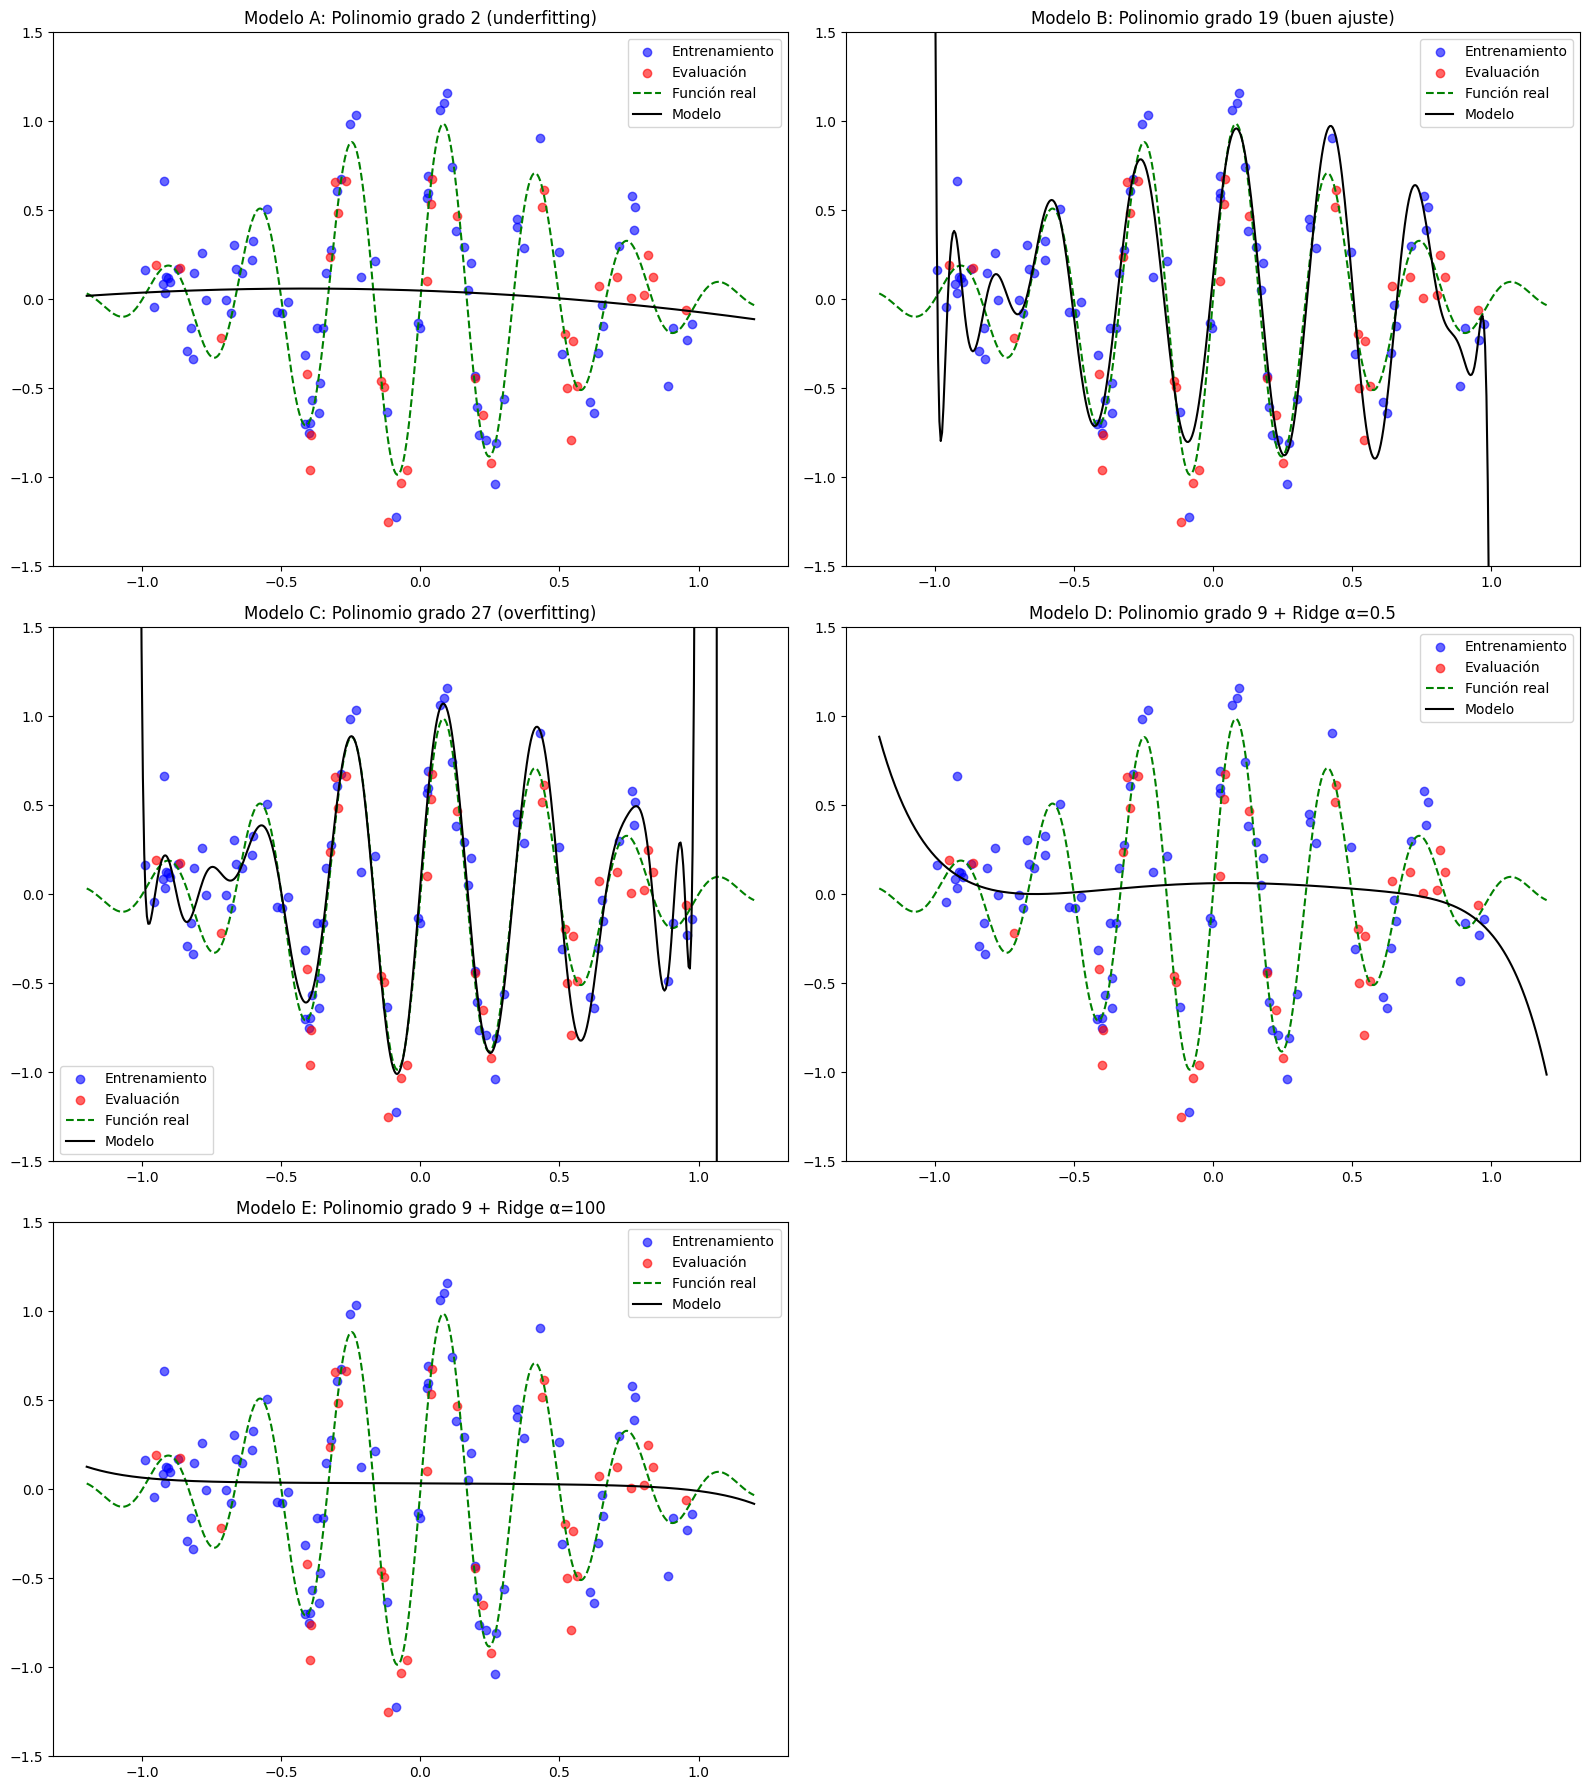

In [21]:
# Graficar
fig, axs = plt.subplots(3, 2, figsize=(16, 18))
axs = axs.ravel()

for i, (title, model) in enumerate(models_new):
    model.fit(Xn_train, yn_train)
    y_pred = model.predict(Xn_plot)

    axs[i].scatter(Xn_train, yn_train, color="blue", label="Entrenamiento", alpha=0.6)
    axs[i].scatter(Xn_test, yn_test, color="red", label="Evaluación", alpha=0.6)
    axs[i].plot(Xn_plot, new_true_function(Xn_plot.ravel()), color="green", linestyle="dashed", label="Función real")
    axs[i].plot(Xn_plot, y_pred, color="black", label="Modelo")
    axs[i].set_title(title)
    axs[i].legend()
    axs[i].set_ylim(-1.5, 1.5)

axs[-1].axis('off')
plt.tight_layout()
plt.show()